In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.io import loadmat


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.io import loadmat

def load_biomass_data(
    parent_path,
    band_opt,
    heading,
    acquisition_mode,
    polarimetric_channel,
    
):
    # Loading data
    # Loading angles
    angles_path = f"{parent_path}{band_opt}/PowerCubeGeocod/AnglesUTM.mat"
    angles_data = loadmat(angles_path)
    IncAngleUTM = angles_data['IncAngleUTM']
    easting_axis = angles_data['easting_axis'].squeeze()
    northing_axis = angles_data['northing_axis'].squeeze()

    # Loading LiDAR data
    lidar_path = f"{parent_path}{band_opt}/PowerCubeGeocod/LidarUTM.mat"
    lidar_data = loadmat(lidar_path)
    LidarCHM = lidar_data['LidarCHM']

    # Loading normalized SAR intensity data cube (coherence?)
    pcube_norm_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeNormUTM.mat"
    pcube_norm_data = loadmat(pcube_norm_path)
    PcubeNormUTM = pcube_norm_data['PcubeNormUTM']
    z_axis = pcube_norm_data['z_axis'].squeeze()

    # Loading SAR intensity data cube
    if band_opt == 'P':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedUTM = sar_intensity_data['PcubeDeRampedUTM']
    elif band_opt == 'L':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedDeBiasedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedDeBiasedUTM = sar_intensity_data['PcubeDeRampedDeBiasedUTM']

    # Determine the indices based on string options
    head_ind = 1 if heading == 'NW' else 2
    mono_bi_ind = 1 if acquisition_mode == 'monostatic' else 2
    pol_ind = {'HH': 1, 'HV': 2, 'VV': 3}[polarimetric_channel]

    return {
        'IncAngleUTM': IncAngleUTM,
        'easting_axis': easting_axis,
        'northing_axis': northing_axis,
        'LidarCHM': LidarCHM,
        'PcubeNormUTM': PcubeNormUTM,
        'z_axis': z_axis,
        'PcubeDeRampedUTM': PcubeDeRampedUTM if band_opt == 'P' else PcubeDeRampedDeBiasedUTM,
        'head_ind': head_ind,
        'mono_bi_ind': mono_bi_ind,
        'pol_ind': pol_ind
    }



def plot_biomass_transect_P(
    parent_path,
    heading,
    acquisition_mode,
    polarimetric_channel,
    P0,
    P1,
    dl
):
    
    band_opt= 'P'
    # Load the data
    data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)

    # Extract the data
    easting_axis = data['easting_axis']
    northing_axis = data['northing_axis']
    LidarCHM = data['LidarCHM']
    z_axis = data['z_axis']
    PcubeDeRampedUTM = data['PcubeDeRampedUTM']
    head_ind = data['head_ind']
    mono_bi_ind = data['mono_bi_ind']
    pol_ind = data['pol_ind']

    # Define start and end points of the transect
    P0 = np.array(P0)
    P1 = np.array(P1)
    P0[1] += 300  # Adjust P0 for better visibility
    P1[1] += 300  # Adjust P1 for better visibility
    i_l = (P1 - P0) / np.linalg.norm(P1 - P0)  # Direction vector normalized
    l_samples = np.vstack([np.arange(P0[0], P1[0], dl * i_l[0]), np.arange(P0[1], P1[1], dl * i_l[1])])  # Sample points
    l_local = np.arange(0, l_samples.shape[1] * dl, dl)  # Local distances
    Nl = l_samples.shape[1]  # Number of samples

    # Define interpolator for each z-slice
    interp_funcs = [
        RegularGridInterpolator(
            (northing_axis, easting_axis),
            PcubeDeRampedUTM[:, :, z_index, pol_ind-1, head_ind-1],
            bounds_error=False,
            fill_value=np.nan
        ) for z_index in range(len(z_axis))
    ]

    # Prepare points for interpolation
    points_to_interpolate = np.stack((l_samples[1, :], l_samples[0, :]), axis=-1)  # Transpose for correct dimensionality

    # Initialize array to store max values for each z-slice and the interpolated stack
    max_values_along_transect = np.zeros(len(z_axis))
    int_stack = np.zeros((len(z_axis), len(l_samples[0, :])))
    print(int_stack.shape)
    # Interpolate and find max values
    for i, func in enumerate(interp_funcs):
        interpolated_values = func(points_to_interpolate)
        int_stack[i] = interpolated_values
        max_value = np.nanmax(interpolated_values)
        max_values_along_transect[i] = max_value

    # Interpolate LiDAR data along the transect
    interp_func_lidar = RegularGridInterpolator((northing_axis, easting_axis), LidarCHM,
                                                method='linear', bounds_error=False, fill_value=np.nan)
    lidar_chm_transect = interp_func_lidar(points_to_interpolate)



    # # Plot the maximum intensity values along the transect for each z-slice
    # plt.figure(figsize=(10, 6))
    # plt.plot(z_axis, max_values_along_transect, 'o-')
    # plt.title('Maximum Intensity Values Along the Transect for Each Z-Slice')
    # plt.xlabel('Elevation (m)')
    # plt.ylabel('Max Intensity (dB)')
    # plt.grid(True)
    # plt.show()

    # Plot the interpolated intensity values along the transect (int_stack) and overlay the LiDAR CHM data
    plt.figure(figsize=(12, 6))
    plt.imshow(int_stack, aspect='auto', extent=[0, l_local[-1] * 1e-3, z_axis.min(), z_axis.max()], origin='lower', cmap='PiYG')
    plt.colorbar(label='Interpolated Intensity (dB)')
    plt.plot(l_local * 1e-3, lidar_chm_transect, 'k-', linewidth=2, label='LiDAR CHM Profile')

    plt.title(f'{band_opt} Band, {heading} Heading, {acquisition_mode}, {polarimetric_channel} Channel')
    plt.xlabel('Distance along transect [km]')
    plt.ylabel('Elevation [m]')
    plt.legend()
    plt.show()


In [ ]:

# Example usage
parent_path = '/home/grace.bcolverd/'
band_opt = 'P'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HV'
# above_ground_elevation = 20

data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)

# Access the returned objects
IncAngleUTM = data['IncAngleUTM']
easting_axis = data['easting_axis']
northing_axis = data['northing_axis']
LidarCHM = data['LidarCHM']
PcubeNormUTM = data['PcubeNormUTM']
z_axis = data['z_axis']
PcubeDeRampedUTM = data['PcubeDeRampedUTM']
head_ind = data['head_ind']
mono_bi_ind = data['mono_bi_ind']
pol_ind = data['pol_ind']


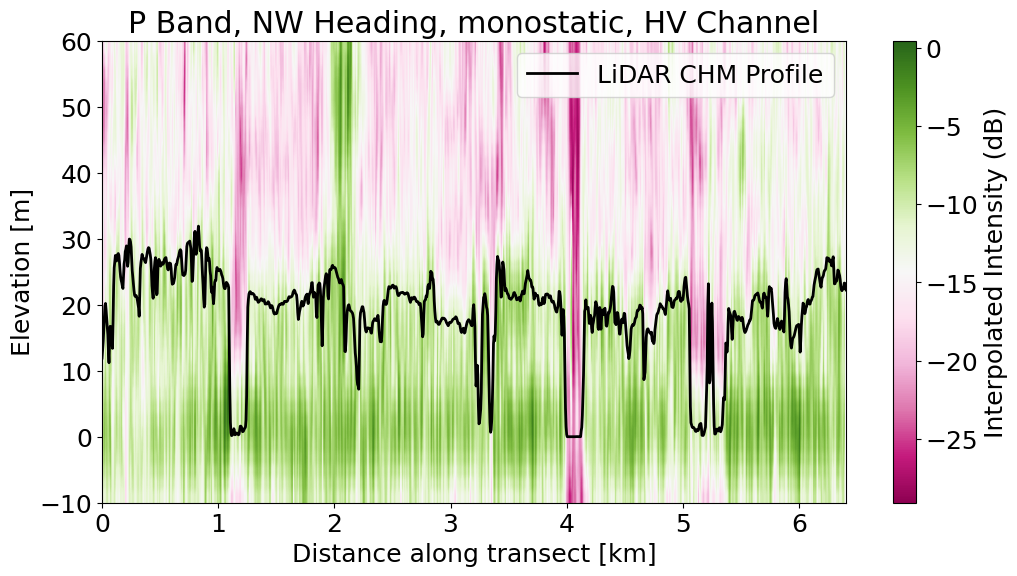

In [30]:

band_opt = 'P'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HV'

P0 = [317100, 5610700]
P1 = [323000, 5608200]
dl = 5

plot_biomass_transect(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel, P0, P1, dl)


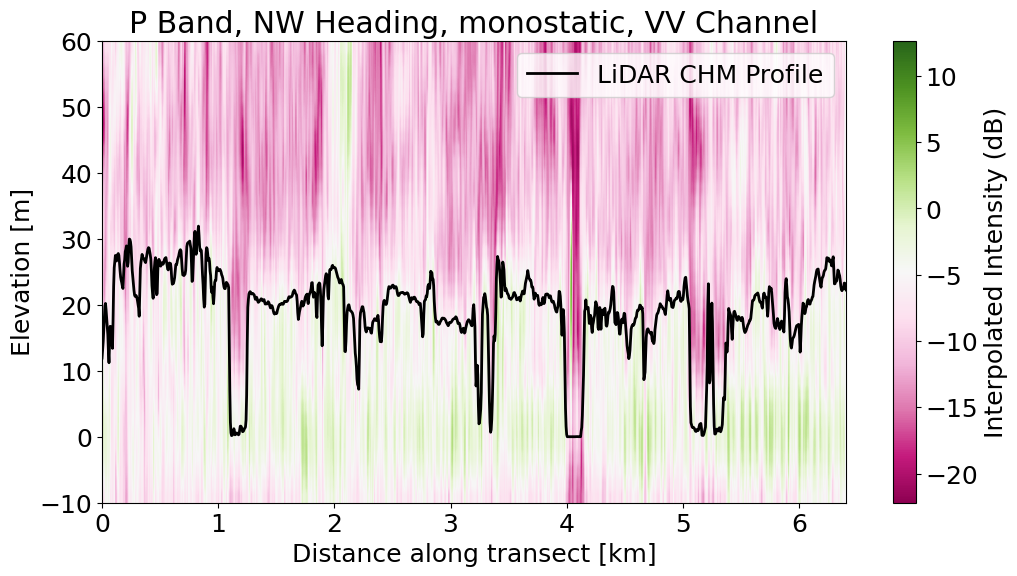

In [31]:

band_opt = 'P'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'VV'

P0 = [317100, 5610700]
P1 = [323000, 5608200]
dl = 5

plot_biomass_transect(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel, P0, P1, dl)


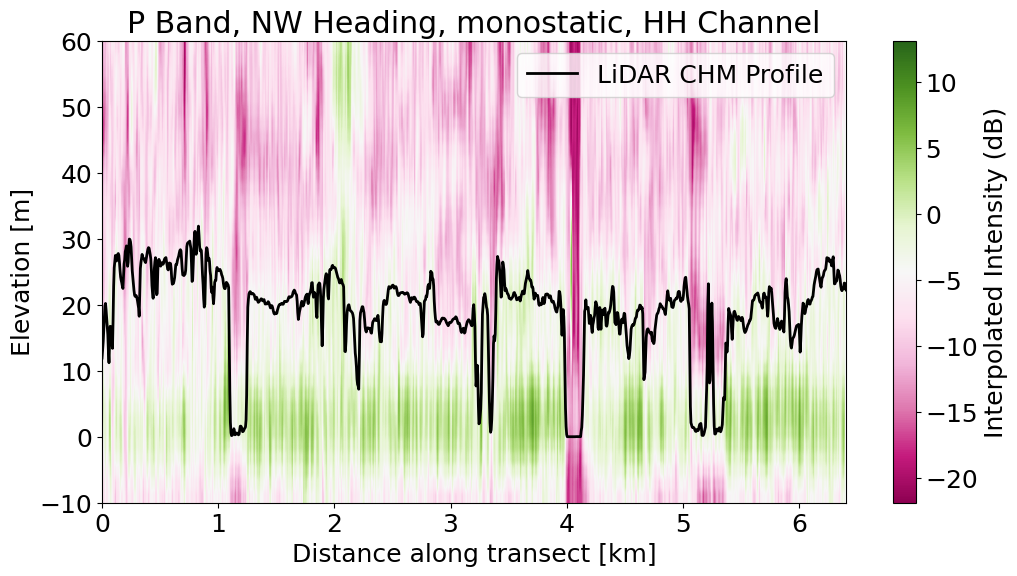

In [32]:

band_opt = 'P'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HH'

P0 = [317100, 5610700]
P1 = [323000, 5608200]
dl = 5

plot_biomass_transect(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel, P0, P1, dl)


In [ ]:

band_opt = 'P'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HH'

P0 = [317100, 5610700]
P1 = [323000, 5608200]
dl = 5

plot_biomass_transect(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel, P0, P1, dl)


In [21]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.io import loadmat
# from scipy.interpolate import interp2d
# from scipy.interpolate import RegularGridInterpolator

# # Options
# parent_path = '/home/grace.bcolverd/'  # Path to the parent directory

# # Either 'P' or 'L'
# band_opt = 'P'  # Band option

# # Loading data
# # Loading angles
# angles_path = f"{parent_path}{band_opt}/PowerCubeGeocod/AnglesUTM.mat"
# angles_data = loadmat(angles_path)
# IncAngleUTM = angles_data['IncAngleUTM']
# easting_axis = angles_data['easting_axis'].squeeze()
# northing_axis = angles_data['northing_axis'].squeeze()

# # Loading LiDAR data
# lidar_path = f"{parent_path}{band_opt}/PowerCubeGeocod/LidarUTM.mat"
# lidar_data = loadmat(lidar_path)
# LidarCHM = lidar_data['LidarCHM']

# # Loading normalized SAR intensity data cube (coherence?)
# pcube_norm_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeNormUTM.mat"
# pcube_norm_data = loadmat(pcube_norm_path)
# PcubeNormUTM = pcube_norm_data['PcubeNormUTM']
# z_axis = pcube_norm_data['z_axis'].squeeze()

# # Loading SAR intensity data cube
# if band_opt == 'P':
#     sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedUTM.mat"
#     sar_intensity_data = loadmat(sar_intensity_path)
#     PcubeDeRampedUTM = sar_intensity_data['PcubeDeRampedUTM']
# elif band_opt == 'L':
#     sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedDeBiasedUTM.mat"
#     sar_intensity_data = loadmat(sar_intensity_path)
#     PcubeDeRampedDeBiasedUTM = sar_intensity_data['PcubeDeRampedDeBiasedUTM']

# # Showing
# heading = 'NW'  # Either 'NW' (290°) or 'SE' (110°)
# acquisition_mode = 'monostatic'  # Either 'monostatic' or 'bistatic'
# polarimetric_channel = 'HV'  # 'HH', 'HV', or 'VV'
# above_ground_elevation = 20  # [m]

# # Determine the indices based on string options
# head_ind = 1 if heading == 'NW' else 2
# mono_bi_ind = 1 if acquisition_mode == 'monostatic' else 2
# pol_ind = {'HH': 1, 'HV': 2, 'VV': 3}[polarimetric_channel]


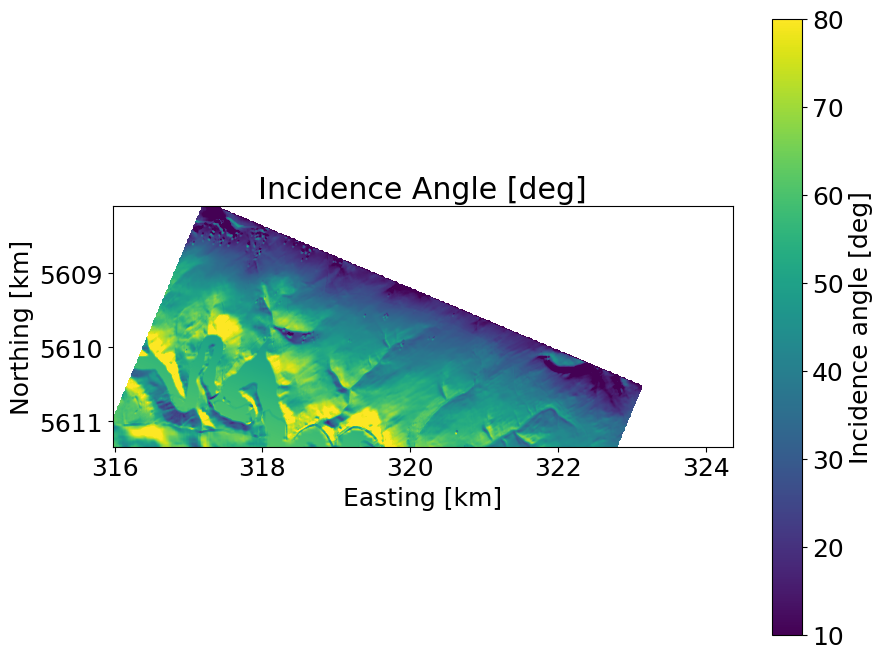

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# Load the data
angles_path = f"{parent_path}{band_opt}/PowerCubeGeocod/AnglesUTM.mat"
angles_data = loadmat(angles_path)
IncAngleUTM = angles_data['IncAngleUTM']
easting_axis = angles_data['easting_axis'].squeeze()
northing_axis = angles_data['northing_axis'].squeeze()

# Convert radians to degrees
IncAngle_deg = IncAngleUTM[:, :, 0] * 180 / np.pi  # Assuming the first index for head_ind

# Create a figure
plt.figure(figsize=(10, 8))

# Display the data as an image
# The `extent` parameter scales the axes from their native units to kilometers
# 'origin' is set to 'lower' to ensure the geographical mapping aligns correctly
plt.imshow(IncAngle_deg, extent=[easting_axis.min()*1e-3, easting_axis.max()*1e-3,
                                 northing_axis.max()*1e-3, northing_axis.min()*1e-3],
           vmin=10, vmax=80, cmap='viridis',  origin='lower')

# Add a colorbar to the right of the plot to show the color scale
plt.colorbar(label='Incidence angle [deg]')

# Set axis labels and title
plt.title('Incidence Angle [deg]')
plt.xlabel('Easting [km]')
plt.ylabel('Northing [km]')

# Enhance font size for better readability
plt.rcParams.update({'font.size': 18})

# Show the plot
plt.show()


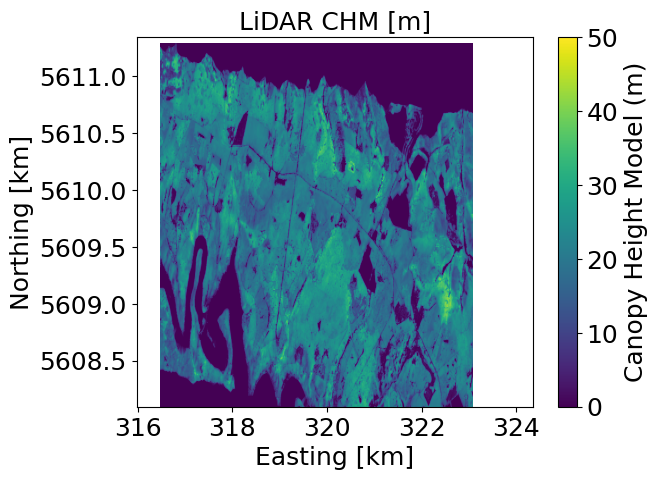

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# Load your data
# Assuming you have already loaded easting_axis, northing_axis, and LidarCHM

# Showing LiDAR data
plt.figure()
plt.imshow(LidarCHM, 
           extent=[easting_axis.min() * 1e-3, easting_axis.max() * 1e-3, 
                   northing_axis.min() * 1e-3, northing_axis.max() * 1e-3], 
           vmin=0, vmax=50,  origin='lower')

# Setting axis properties
plt.axis('tight')
plt.colorbar(label='Canopy Height Model (m)')
plt.title('LiDAR CHM [m]', fontsize=18)
plt.xlabel('Easting [km]', fontsize=18)
plt.ylabel('Northing [km]', fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()


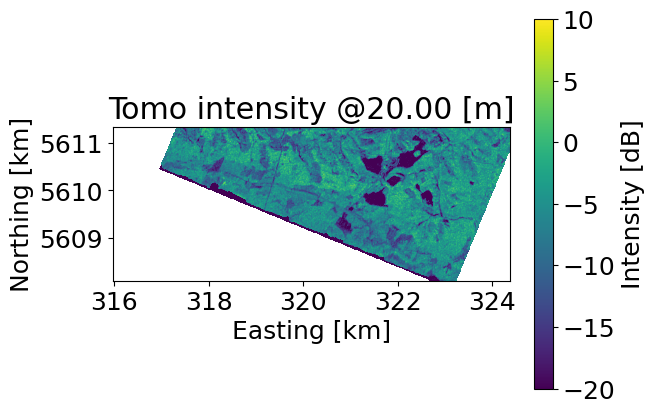

In [16]:
import numpy as np
import matplotlib.pyplot as plt

if band_opt == 'P':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedUTM = sar_intensity_data['PcubeDeRampedUTM']
elif band_opt=='L':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedDeBiasedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedDeBiasedUTM = sar_intensity_data['PcubeDeRampedDeBiasedUTM']
 
# Find the index of the closest value in z_axis to the given 'above_ground_elevation'
z_ind = np.argmin(np.abs(z_axis - above_ground_elevation))

# Choose the dataset based on the 'band_opt' and display the image
if band_opt == 'P':
        plt.figure()
        plt.imshow(PcubeDeRampedUTM[:, :, z_ind, pol_ind, head_ind], 
                extent=(easting_axis.min() * 1e-3, easting_axis.max() * 1e-3,
                        northing_axis.min() * 1e-3, northing_axis.max() * 1e-3),
                aspect='auto', origin='lower', vmin=-20, vmax=10)
elif band_opt == 'L':
        plt.figure()
        plt.imshow(PcubeDeRampedDeBiasedUTM[:, :, z_ind, pol_ind, mono_bi_ind, head_ind],
                extent=(easting_axis.min() * 1e-3, easting_axis.max() * 1e-3,
                        northing_axis.min() * 1e-3, northing_axis.max() * 1e-3),
                aspect='auto', origin='lower', vmin=-20, vmax=10)

# Set additional plot properties
plt.axis('tight')
plt.colorbar(label='Intensity [dB]')
plt.title(f'Tomo intensity @{z_axis[z_ind]:.2f} [m]')
plt.xlabel('Easting [km]')
plt.ylabel('Northing [km]')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()


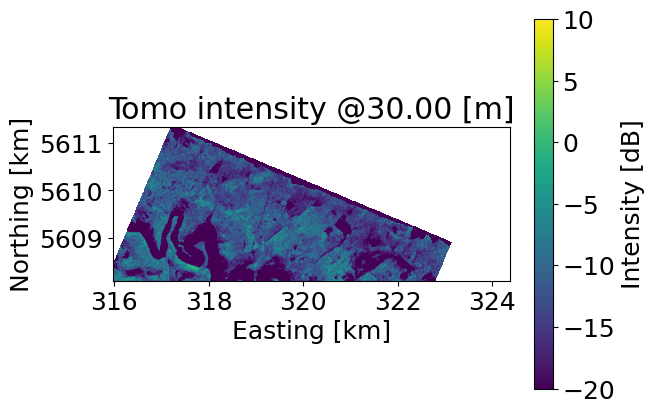

In [17]:
import numpy as np
import matplotlib.pyplot as plt
above_ground_elevation=30
# Find the index of the closest value in z_axis to the given 'above_ground_elevation'
z_ind = np.argmin(np.abs(z_axis - above_ground_elevation))

# Choose the dataset based on the 'band_opt' and display the image
if band_opt == 'P':
    plt.figure()
    plt.imshow(PcubeDeRampedUTM[:, :, z_ind, pol_ind-1, head_ind-1], 
               extent=(easting_axis.min() * 1e-3, easting_axis.max() * 1e-3,
                       northing_axis.min() * 1e-3, northing_axis.max() * 1e-3),
               aspect='auto', origin='lower', vmin=-20, vmax=10)
elif band_opt == 'L':
    plt.figure()
    plt.imshow(PcubeDeRampedDeBiasedUTM[:, :, z_ind, pol_ind, mono_bi_ind, head_ind],
               extent=(easting_axis.min() * 1e-3, easting_axis.max() * 1e-3,
                       northing_axis.min() * 1e-3, northing_axis.max() * 1e-3),
               aspect='auto', origin='lower', vmin=-20, vmax=10)

# Set additional plot properties
plt.axis('tight')
plt.colorbar(label='Intensity [dB]')
plt.title(f'Tomo intensity @{z_axis[z_ind]:.2f} [m]')
plt.xlabel('Easting [km]')
plt.ylabel('Northing [km]')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()


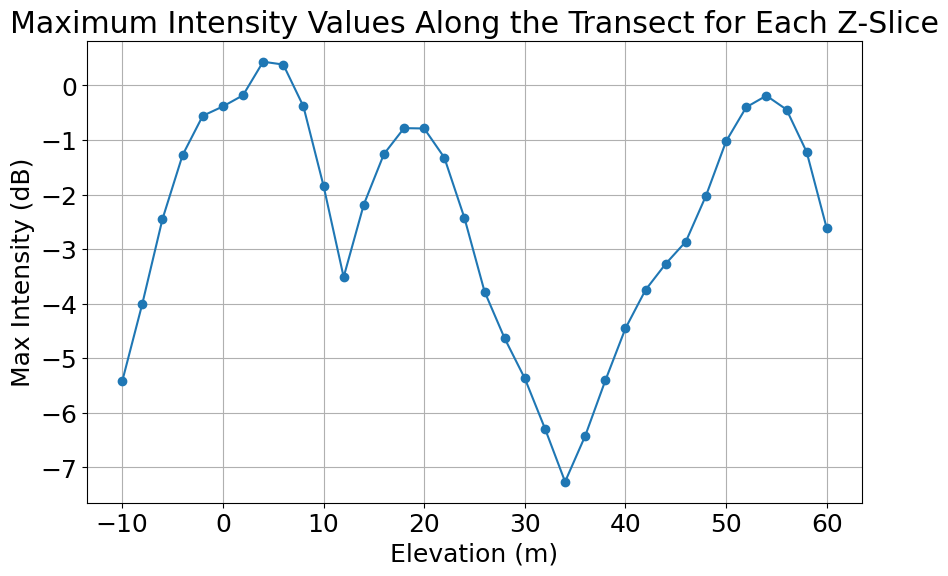

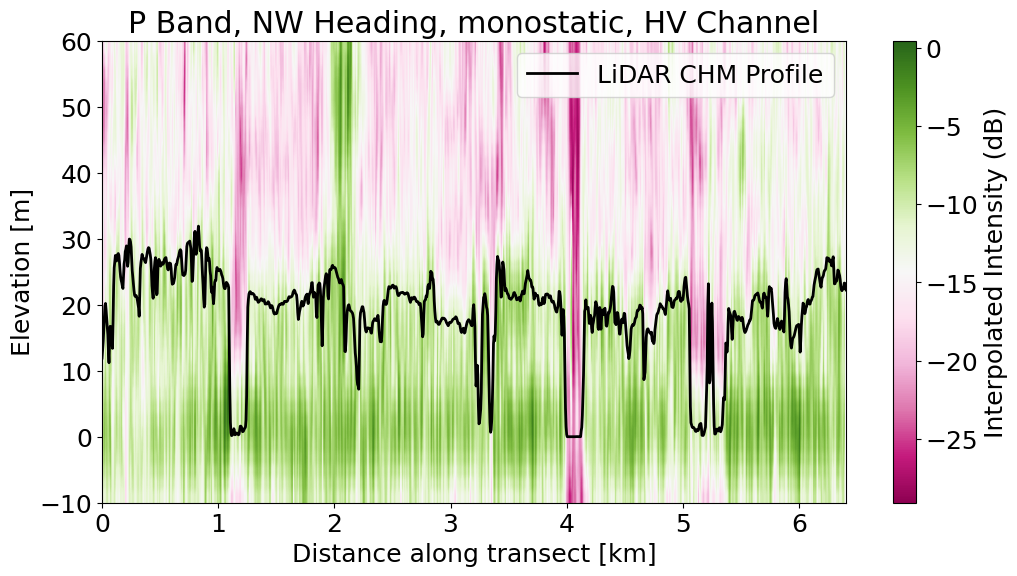

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator

# Define start and end points of the transect
P0 = np.array([317100, 5610700])  # Starting point
P1 = np.array([323000, 5608200])  # Ending point
dl = 5  # Distance increment
P0[1] += 300  # Adjust P0 for better visibility
P1[1] += 300  # Adjust P1 for better visibility
i_l = (P1 - P0) / np.linalg.norm(P1 - P0)  # Direction vector normalized
l_samples = np.vstack([np.arange(P0[0], P1[0], dl * i_l[0]), np.arange(P0[1], P1[1], dl * i_l[1])])  # Sample points
l_local = np.arange(0, l_samples.shape[1] * dl, dl)  # Local distances
Nl = l_samples.shape[1]  # Number of samples


# Define interpolator for each z-slice
interp_funcs = [
    RegularGridInterpolator(
        (northing_axis, easting_axis),
        PcubeDeRampedUTM[:, :, z_index, pol_ind-1, head_ind-1],
        bounds_error=False,
        fill_value=np.nan
    ) for z_index in range(len(z_axis))
]

# Prepare points for interpolation
points_to_interpolate = np.stack((l_samples[1, :], l_samples[0, :]), axis=-1)  # Transpose for correct dimensionality

# Initialize array to store max values for each z-slice and the interpolated stack
max_values_along_transect = np.zeros(len(z_axis))
int_stack = np.zeros((len(z_axis), len(l_samples[0, :])))

# Interpolate and find max values
for i, func in enumerate(interp_funcs):
    interpolated_values = func(points_to_interpolate)
    
    int_stack[i] = interpolated_values
    max_value = np.nanmax(interpolated_values)
    max_values_along_transect[i] = max_value


# Interpolate LiDAR data along the transect
interp_func_lidar = RegularGridInterpolator((northing_axis, easting_axis), LidarCHM,
                                            method='linear', bounds_error=False, fill_value=np.nan)
lidar_chm_transect = interp_func_lidar(points_to_interpolate)

# Plot the maximum intensity values along the transect for each z-slice
plt.figure(figsize=(10, 6))
plt.plot(z_axis, max_values_along_transect, 'o-')
plt.title('Maximum Intensity Values Along the Transect for Each Z-Slice')
plt.xlabel('Elevation (m)')
plt.ylabel('Max Intensity (dB)')
plt.grid(True)
plt.show()

# Plot the interpolated intensity values along the transect (int_stack) and overlay the LiDAR CHM data
plt.figure(figsize=(12, 6))
plt.imshow(int_stack, aspect='auto', extent=[0, l_local[-1] * 1e-3, z_axis.min(), z_axis.max()], origin='lower', cmap='PiYG')
plt.colorbar(label='Interpolated Intensity (dB)')
plt.plot(l_local * 1e-3, lidar_chm_transect, 'k-', linewidth=2, label='LiDAR CHM Profile')

plt.title(f'{band_opt} Band, {heading} Heading, {acquisition_mode}, {polarimetric_channel} Channel')
plt.xlabel('Distance along transect [km]')
plt.ylabel('Elevation [m]')
plt.legend()
plt.show()
